<a href="https://colab.research.google.com/github/hamagami/IS2026/blob/main/03_GRU_time_series.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GRU: 時系列予測と自己回帰生成 / GRU: Time-series prediction and autoregressive generation




## 観察すること / What to observe
- GRUで，過去30点から次の値を予測します．
  Use GRU to predict the next value from the previous 30 observations.
- 1ステップ予測と，予測を自分に戻す長期生成を比べます．
  Compare one-step predictions with long-horizon generation that feeds predictions back as inputs.
- 更新・リセットゲートで隠れ状態を更新します．**PyTorchは** $h_t=(1-z_t)\odot\tilde h_t+z_t\odot h_{t-1}$ **という規約**です．講義の「大きいzほど新しい候補」と逆です．また候補計算でのresetの適用位置も講義のreset-before式と異なります．機構の比較として使い，ゲート値を直接同一視しないでください．
  Update and reset gates control the hidden state. **PyTorch uses** $h_t=(1-z_t)\odot\tilde h_t+z_t\odot h_{t-1}$, so a larger z retains more of the previous state, opposite to the lecture convention. PyTorch also applies reset differently from the reset-before candidate equation in the lecture. Compare mechanisms rather than equating gate values.

01〜03は同じデータ・隠れ次元・学習設定です．容易な課題なので，LSTM/GRUの優位性を証明する実験ではありません．

Notebooks 01–03 use identical data, hidden dimensions, and training settings. This easy task does not establish the superiority of LSTM or GRU.


## 準備 / Setup


In [ ]:
import sys, subprocess, importlib.util
# Colabの既存PyTorchを優先し，不足パッケージだけ追加します． / Reuse Colab packages; install only missing dependencies.
for module, package in [('torch','torch'), ('sklearn','scikit-learn'), ('ipywidgets','ipywidgets')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])
import random, math, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
import ipywidgets as widgets
from IPython.display import display, clear_output
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(2)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.dpi':110, 'font.size':11, 'axes.spines.top':False, 'axes.spines.right':False})
print('PyTorch:', torch.__version__, '| 実行機器 / Device:', device)


# 日本語フォントを設定します． / Configure a Japanese font for bilingual figures.
if importlib.util.find_spec('japanize_matplotlib') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'japanize-matplotlib'])
import japanize_matplotlib
plt.rcParams['axes.unicode_minus'] = False


PyTorch: 2.14.1+cpu | 実行機器 / Device: cpu


## 設定 / Configuration


In [ ]:
MODEL_KIND = 'GRU'
WINDOW = 30
HIDDEN = 32
EPOCHS = 12
N_TRAIN = 1400
BATCH_SIZE = 64
LEARNING_RATE = 0.003


## データ / Data


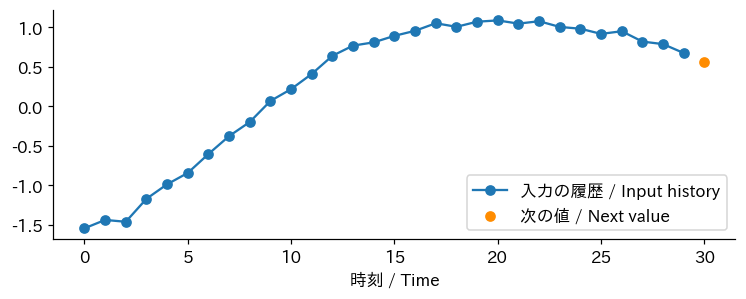

In [ ]:
def make_data(n, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(WINDOW+1,dtype=np.float32)[None,:]
    phase = rng.uniform(0,2*np.pi,(n,1))
    freq = rng.uniform(0.08,0.22,(n,1))
    amp = rng.uniform(.7,1.3,(n,1))
    clean = amp*np.sin(freq*t+phase) + .25*np.sin(2*freq*t+phase)
    noisy = clean + rng.normal(0,.04,clean.shape)
    return torch.tensor(noisy[:,:-1,None],dtype=torch.float32), torch.tensor(clean[:,-1,None],dtype=torch.float32)
Xtr,Ytr = make_data(N_TRAIN,SEED)
Xte,Yte = make_data(300,SEED+1)  # 独立した系列．窓の重複による評価漏洩を避けます． / Use independent series to avoid leakage from overlapping windows.
train_loader = DataLoader(TensorDataset(Xtr,Ytr),batch_size=BATCH_SIZE,shuffle=True)
plt.figure(figsize=(8,2.7)); plt.plot(Xtr[0,:,0], 'o-', label='入力の履歴 / Input history')
plt.scatter([WINDOW],Ytr[0],c='darkorange',label='次の値 / Next value'); plt.legend(); plt.xlabel('時刻 / Time'); plt.show()


## モデル / Model


In [ ]:
class Predictor(nn.Module):
    def __init__(self):
        super().__init__()
        self.core = getattr(nn,MODEL_KIND)(1,HIDDEN,batch_first=True)
        self.readout = nn.Linear(HIDDEN,1)
    def forward(self,x):
        sequence,state = self.core(x)
        return self.readout(sequence[:,-1])
model = Predictor().to(device)
optimizer = torch.optim.Adam(model.parameters(),lr=LEARNING_RATE)
print(model)
print('学習可能なパラメータ数 / Trainable parameters:',sum(p.numel() for p in model.parameters()))


Predictor(
  (core): GRU(1, 32, batch_first=True)
  (readout): Linear(in_features=32, out_features=1, bias=True)
)
学習可能なパラメータ数 / Trainable parameters: 3393


## 学習 / Training


エポック / Epoch  1: 訓練 / train=0.28125, 評価 / held-out=0.10189
エポック / Epoch  3: 訓練 / train=0.00944, 評価 / held-out=0.00862
エポック / Epoch  6: 訓練 / train=0.00551, 評価 / held-out=0.00488
エポック / Epoch  9: 訓練 / train=0.00450, 評価 / held-out=0.00380
エポック / Epoch 12: 訓練 / train=0.00433, 評価 / held-out=0.00366


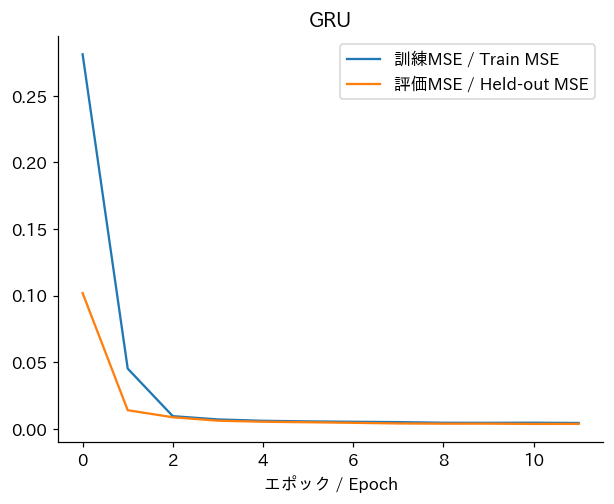

In [ ]:
history=[]
for epoch in range(EPOCHS):
    model.train(); total=0
    for xb,yb in train_loader:
        xb,yb=xb.to(device),yb.to(device)
        optimizer.zero_grad(); loss=F.mse_loss(model(xb),yb)
        loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); optimizer.step()
        total += loss.item()*len(xb)
    model.eval()
    with torch.no_grad(): test_loss=F.mse_loss(model(Xte.to(device)),Yte.to(device)).item()
    history.append((total/len(Xtr),test_loss))
    if epoch==0 or (epoch+1)%3==0: print(f'エポック / Epoch {epoch+1:2d}: 訓練 / train={history[-1][0]:.5f}, 評価 / held-out={test_loss:.5f}')
plt.plot(history); plt.legend(['訓練MSE / Train MSE','評価MSE / Held-out MSE']); plt.xlabel('エポック / Epoch'); plt.title(MODEL_KIND); plt.show()


## 評価と可視化 / Evaluation and visualization


モデルの評価MSE / Held-out model MSE: 0.003658290719613433
直前値を使う基準のMSE / Persistence baseline MSE: 0.01928151212632656


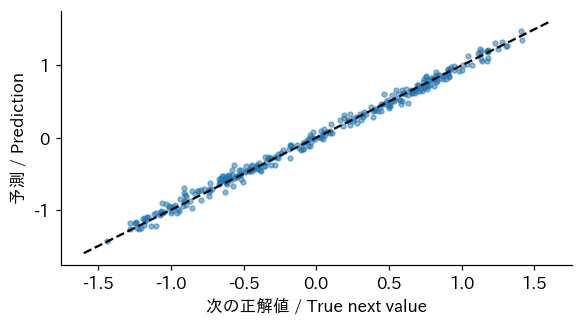

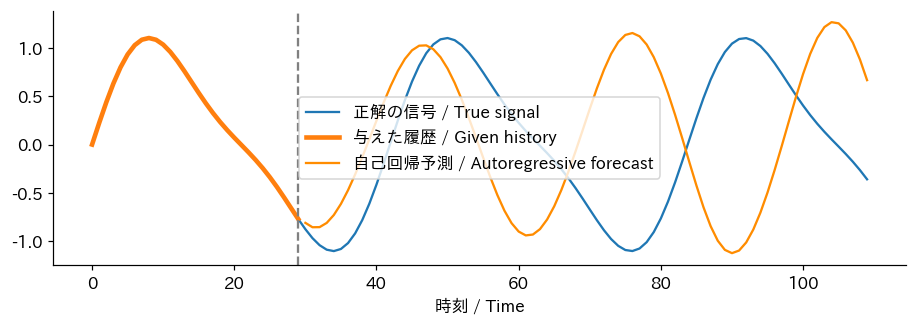

In [ ]:
model.eval()
with torch.no_grad(): pred=model(Xte.to(device)).cpu()
naive=Xte[:,-1,0:1]
print('モデルの評価MSE / Held-out model MSE:',F.mse_loss(pred,Yte).item())
print('直前値を使う基準のMSE / Persistence baseline MSE:',F.mse_loss(naive,Yte).item())
plt.figure(figsize=(6,3));plt.scatter(Yte[:,0],pred[:,0],s=10,alpha=.5)
plt.plot([-1.6,1.6],[-1.6,1.6],'k--');plt.xlabel('次の正解値 / True next value');plt.ylabel('予測 / Prediction');plt.show()
def show_sequence(sample=0, steps=80):
    # 長期生成中は正解値を入力せず，自分の予測を戻します． / Feed predictions back without using true future values.
    model.eval()
    t=np.arange(WINDOW+steps,dtype=np.float32)
    true=np.sin(.15*t+sample*.3)+.25*np.sin(.30*t+sample*.3)
    context=torch.tensor(true[:WINDOW],dtype=torch.float32).reshape(1,WINDOW,1).to(device)
    generated=[]
    with torch.no_grad():
        for _ in range(steps):
            value=model(context); generated.append(value.item())
            context=torch.cat([context[:,1:],value.reshape(1,1,1)],dim=1)
    fig,ax=plt.subplots(figsize=(10,3))
    ax.plot(t,true,label='正解の信号 / True signal');ax.plot(t[:WINDOW],true[:WINDOW],lw=3,label='与えた履歴 / Given history')
    ax.plot(t[WINDOW:],generated,label='自己回帰予測 / Autoregressive forecast',color='darkorange')
    ax.axvline(WINDOW-1,color='gray',ls='--');ax.legend();ax.set_xlabel('時刻 / Time');plt.show()
show_sequence()


## インタラクティブ操作 / Interactive controls


In [ ]:
widgets.interact(show_sequence, sample=widgets.IntSlider(min=0,max=12,value=0,description='位相 / Phase', style={'description_width':'initial'}, layout=widgets.Layout(width='auto',min_width='260px')),
                 steps=widgets.IntSlider(min=10,max=150,value=80,description='予測期間 / Forecast', style={'description_width':'initial'}, layout=widgets.Layout(width='auto',min_width='260px')))


interactive(children=(IntSlider(value=0, description='位相 / Phase', layout=Layout(min_width='260px', width='aut…

<function __main__.show_sequence(sample=0, steps=80)>

## 講義中の問い / Questions for discussion
- 1ステップMSEが小さくても，長期予測がずれるのはなぜでしょうか．
  Why can long-horizon forecasts drift even when the one-step MSE is small?
- WINDOW，HIDDEN，EPOCHSを変えて再実行してください．
  Change WINDOW, HIDDEN, and EPOCHS and run the notebook again.
- 入力は各予測窓で状態を初期化します．全系列を一つの状態で連続処理する設定とは異なります．
  The state is initialized for each prediction window. This differs from processing an entire sequence continuously with one carried state.


## 参考 / References
- [PyTorch GRU](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html)
